# Fase 2 - Comprensión de los datos

## 2.1 Carga de datos

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "bank-full.csv").is_file() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
DATA_PATH = ROOT / "Data" / "bank-full.csv"
MODELS_DIR = ROOT / "Modelos"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(DATA_PATH, sep=";")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2.2 Estructura y tipos de datos

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


## 2.3 Calidad de datos: valores faltantes y duplicados

In [3]:
print("Valores nulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "Sin valores nulos")
print("\nFilas duplicadas:", df.duplicated().sum())
print("\nCategorias 'unknown' por variable:")
unk = (df.select_dtypes(include=["object", "string"]) == "unknown").sum()
print(unk[unk > 0])

Valores nulos por columna:
Sin valores nulos

Filas duplicadas: 0

Categorias 'unknown' por variable:
job            288
education     1857
contact      13020
poutcome     36959
dtype: int64


## 2.4 Variable objetivo

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


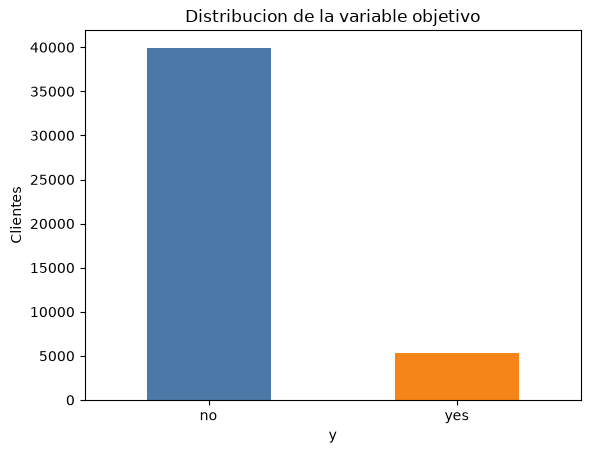

In [4]:
print(df["y"].value_counts())
print((df["y"].value_counts(normalize=True) * 100).round(2))
df["y"].value_counts().plot(kind="bar", color=["#4C78A8", "#F58518"], title="Distribucion de la variable objetivo")
plt.ylabel("Clientes"); plt.xticks(rotation=0); plt.show()

## 2.5 Resumen descriptivo de variables numéricas

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


## 2.6 Valores atípicos (regla IQR)

In [6]:
num = df.select_dtypes(include="number").columns
rows = []
for c in num:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    rows.append({"variable": c, "outliers_IQR": n, "porcentaje": round(100 * n / len(df), 2)})
pd.DataFrame(rows).sort_values("outliers_IQR", ascending=False)

,variable,outliers_IQR,porcentaje
6,previous,8257,18.26
5,pdays,8257,18.26
1,balance,4729,10.46
3,duration,3235,7.16
4,campaign,3064,6.78
0,age,487,1.08
2,day,0,0.00


## 2.7 Relación con el objetivo y correlaciones

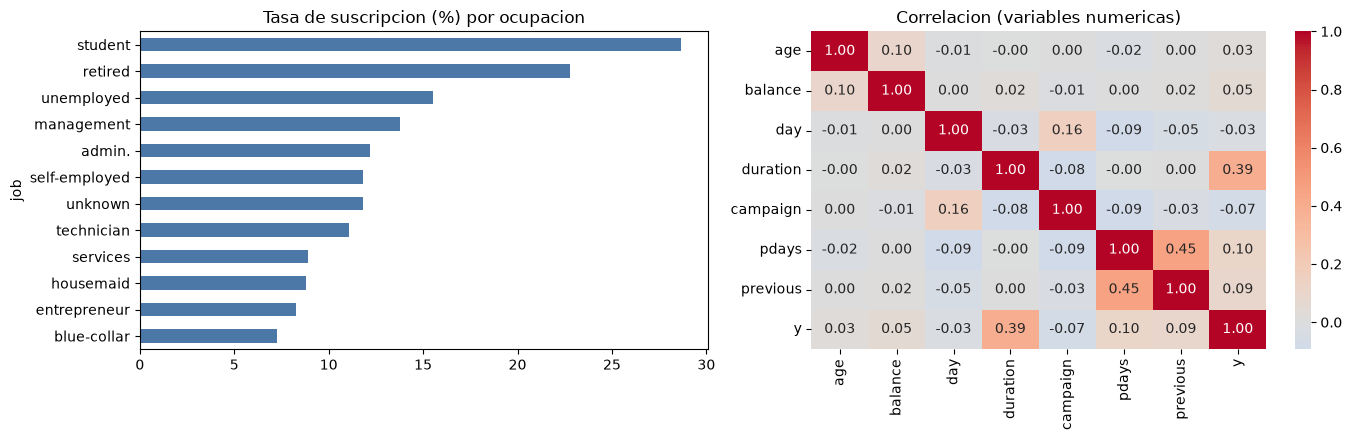

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rate = (df.assign(y_bin=df["y"].eq("yes").astype(int)).groupby("job")["y_bin"].mean().sort_values() * 100)
rate.plot(kind="barh", ax=axes[0], color="#4C78A8", title="Tasa de suscripcion (%) por ocupacion")
corr = df.select_dtypes(include="number").assign(y=df["y"].eq("yes").astype(int)).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Correlacion (variables numericas)")
plt.tight_layout(); plt.show()

## 2.8 Hallazgos iniciales
- El dataset tiene **45.211 filas y 17 columnas**; no contiene nulos ni duplicados exactos.
- La variable objetivo está **desbalanceada**: ≈ 88,3 % `no` y ≈ 11,7 % `yes`. Accuracy sería engañosa; se usarán Recall, F1, ROC-AUC y PR-AUC.
- Las categorías `unknown` (p. ej. `poutcome`, `contact`, `education`) son valores explícitos y se conservan como categoría.
- `balance`, `pdays`, `previous` y `campaign` presentan valores extremos; pueden corresponder a clientes legítimos, por lo que **no se eliminan** automáticamente.
- `duration`, `campaign`, `day`, `month` y `contact` describen el contacto en curso; se excluirán en la Fase 3 para evitar fuga de información.

## Checklist Fase 2
- [x] Dimensiones y tipos revisados
- [x] Nulos y duplicados auditados
- [x] Distribución del objetivo analizada
- [x] Outliers detectados (sin eliminar)
- [x] Hallazgos documentados